# Further Work: Machine Learning-Based Event Selection

### Aim
To investigate whether machine learning can improve the signal purity and efficiency of muon-neutrino charged-current event selection compared with the original cut-based method.

### Approach
Train a binary Random Forest classifier to distinguish signal (category 21) from background events, and evaluate its performance using weighted purity and signal efficiency.


In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Load the same cleaned baseline used in the main analysis
MC_ML = pd.read_pickle("data/MC_EXT_flattened.pkl")
MC_ML = MC_ML.drop("Subevent", axis=1)

MC_ML = MC_ML.loc[
    MC_ML["trk_energy_tot"] < 1000
].copy().reset_index(drop=True)

# Reconstructed features from Exercise 6
features = [
    "_closestNuCosmicDist",
    "trk_len_v",
    "trk_distance_v",
    "topological_score",
    "trk_sce_end_z_v",
    "trk_sce_end_y_v",
    "trk_sce_end_x_v",
    "trk_score_v",
    "trk_llr_pid_score_v",
    "trk_sce_start_z_v",
    "trk_sce_start_y_v",
    "trk_sce_start_x_v",
    "reco_nu_vtx_sce_x",
    "reco_nu_vtx_sce_y",
    "reco_nu_vtx_sce_z",
    "trk_energy_tot"
]

# Binary signal/background classification
X = MC_ML[features]
y = (MC_ML["category"] == 21).astype(int)
weights = MC_ML["weight"]

print("Features:", X.shape)
print("Labels:", y.shape)
print("Class counts:")
print(y.value_counts())
print("Missing feature values:", X.isna().sum().sum())


Features: (150365, 16)
Labels: (150365,)
Class counts:
category
1    110114
0     40251
Name: count, dtype: int64
Missing feature values: 0


In [2]:
# First split: 80% development, 20% test
X_dev, X_test, y_dev, y_test, w_dev, w_test = train_test_split(
    X, y, weights,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Second split: 60% training, 20% validation
X_train, X_val, y_train, y_val, w_train, w_val = train_test_split(
    X_dev, y_dev, w_dev,
    test_size=0.25,
    random_state=42,
    stratify=y_dev
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Training: (90219, 16)
Validation: (30073, 16)
Test: (30073, 16)


In [3]:
# Initial binary Random Forest model
rf_binary = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=10,
    criterion="gini",
    random_state=42,
    n_jobs=-1
)

rf_binary.fit(
    X_train,
    y_train,
    sample_weight=w_train
)

# Predict signal probabilities on validation data
signal_scores = rf_binary.predict_proba(X_val)[:, 1]

print("Validation scores:", signal_scores.shape)
print("Score range:", signal_scores.min(), signal_scores.max())


Validation scores: (30073,)
Score range: 0.015534885392297453 0.9821854810971911


In [4]:
# Calculate weighted purity and signal efficiency
def selection_metrics(selected, labels, weights):
    selected = np.asarray(selected, dtype=bool)
    labels = np.asarray(labels, dtype=bool)
    weights = np.asarray(weights)

    signal_before = weights[labels].sum()
    signal_after = weights[selected & labels].sum()
    total_after = weights[selected].sum()

    purity = signal_after / total_after if total_after > 0 else np.nan
    efficiency = signal_after / signal_before

    return purity, efficiency


In [5]:
# Common reconstructed-energy window
energy_window = (
    (X_val["trk_energy_tot"] > 0) &
    (X_val["trk_energy_tot"] < 2)
).to_numpy()

# Original manual selection
manual_selected = (
    energy_window &
    X_val["reco_nu_vtx_sce_x"].between(10, 245, inclusive="neither").to_numpy() &
    X_val["reco_nu_vtx_sce_y"].between(-100, 100, inclusive="neither").to_numpy() &
    X_val["reco_nu_vtx_sce_z"].between(20, 1000, inclusive="neither").to_numpy() &
    (X_val["topological_score"] > 0.2).to_numpy()
)

manual_purity, manual_efficiency = selection_metrics(
    manual_selected, y_val, w_val
)

print(f"Manual purity: {manual_purity:.2%}")
print(f"Manual efficiency: {manual_efficiency:.2%}")


Manual purity: 85.75%
Manual efficiency: 73.41%


Manual purity: 85.75%
Manual efficiency: 73.41%
RF threshold: 0.745
RF purity: 90.55%
RF efficiency: 73.27%


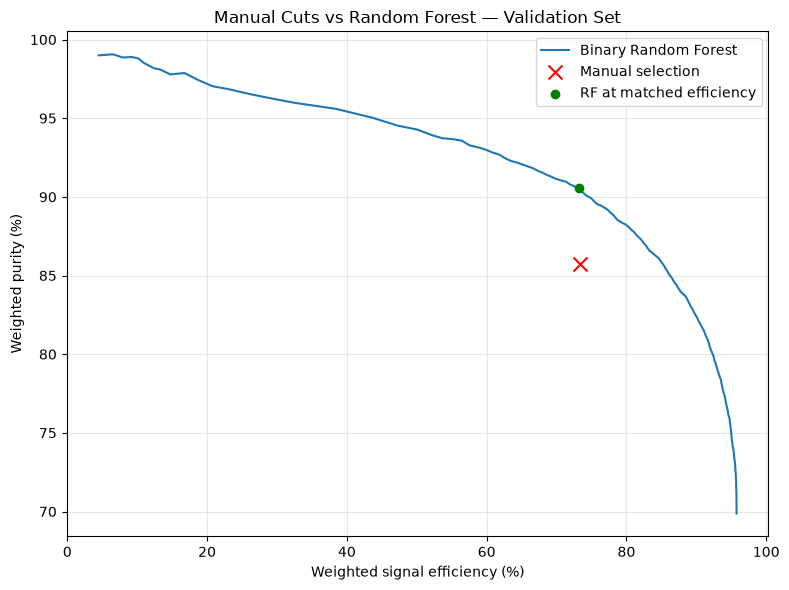

In [7]:
# Evaluate Random Forest at different score thresholds

import matplotlib.pyplot as plt
thresholds = np.linspace(0, 1, 201)

rf_purities = []
rf_efficiencies = []

for threshold in thresholds:
    rf_selected = energy_window & (signal_scores >= threshold)

    purity, efficiency = selection_metrics(
        rf_selected, y_val, w_val
    )

    rf_purities.append(purity)
    rf_efficiencies.append(efficiency)

rf_purities = np.array(rf_purities)
rf_efficiencies = np.array(rf_efficiencies)

# Find the RF threshold closest to manual efficiency
best_idx = np.argmin(np.abs(rf_efficiencies - manual_efficiency))

print(f"Manual purity: {manual_purity:.2%}")
print(f"Manual efficiency: {manual_efficiency:.2%}")
print(f"RF threshold: {thresholds[best_idx]:.3f}")
print(f"RF purity: {rf_purities[best_idx]:.2%}")
print(f"RF efficiency: {rf_efficiencies[best_idx]:.2%}")

# Plot the performance comparison
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    rf_efficiencies * 100,
    rf_purities * 100,
    label="Binary Random Forest"
)

ax.scatter(
    manual_efficiency * 100,
    manual_purity * 100,
    color="red",
    marker="x",
    s=100,
    label="Manual selection",
    zorder=5
)

ax.scatter(
    rf_efficiencies[best_idx] * 100,
    rf_purities[best_idx] * 100,
    color="green",
    marker="o",
    label="RF at matched efficiency",
    zorder=5
)

ax.set_xlabel("Weighted signal efficiency (%)")
ax.set_ylabel("Weighted purity (%)")
ax.set_title("Manual Cuts vs Random Forest — Validation Set")

ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [8]:
# Predict signal probabilities on test data
test_scores = rf_binary.predict_proba(X_test)[:, 1]

energy_window_test = (
    (X_test["trk_energy_tot"] > 0) &
    (X_test["trk_energy_tot"] < 2)
).to_numpy()

manual_selected_test = (
    energy_window_test &
    X_test["reco_nu_vtx_sce_x"].between(10, 245, inclusive="neither").to_numpy() &
    X_test["reco_nu_vtx_sce_y"].between(-100, 100, inclusive="neither").to_numpy() &
    X_test["reco_nu_vtx_sce_z"].between(20, 1000, inclusive="neither").to_numpy() &
    (X_test["topological_score"] > 0.2).to_numpy()
)

rf_selected_test = energy_window_test & (test_scores >= 0.745)

manual_purity_test, manual_efficiency_test = selection_metrics(
    manual_selected_test, y_test, w_test
)

rf_purity_test, rf_efficiency_test = selection_metrics(
    rf_selected_test, y_test, w_test
)

print(f"Manual test purity: {manual_purity_test:.2%}")
print(f"Manual test efficiency: {manual_efficiency_test:.2%}")
print(f"RF test purity: {rf_purity_test:.2%}")
print(f"RF test efficiency: {rf_efficiency_test:.2%}")

Manual test purity: 85.97%
Manual test efficiency: 73.01%
RF test purity: 90.21%
RF test efficiency: 72.23%


### Feature importance

                 feature  importance
3      topological_score    0.481562
15        trk_energy_tot    0.122226
0   _closestNuCosmicDist    0.066506
8    trk_llr_pid_score_v    0.058349
5        trk_sce_end_y_v    0.048208
13     reco_nu_vtx_sce_y    0.041476
1              trk_len_v    0.031429
10     trk_sce_start_y_v    0.026128
7            trk_score_v    0.024541
2         trk_distance_v    0.022024
12     reco_nu_vtx_sce_x    0.017016
11     trk_sce_start_x_v    0.014418
4        trk_sce_end_z_v    0.013507
14     reco_nu_vtx_sce_z    0.012253
9      trk_sce_start_z_v    0.010517
6        trk_sce_end_x_v    0.009840


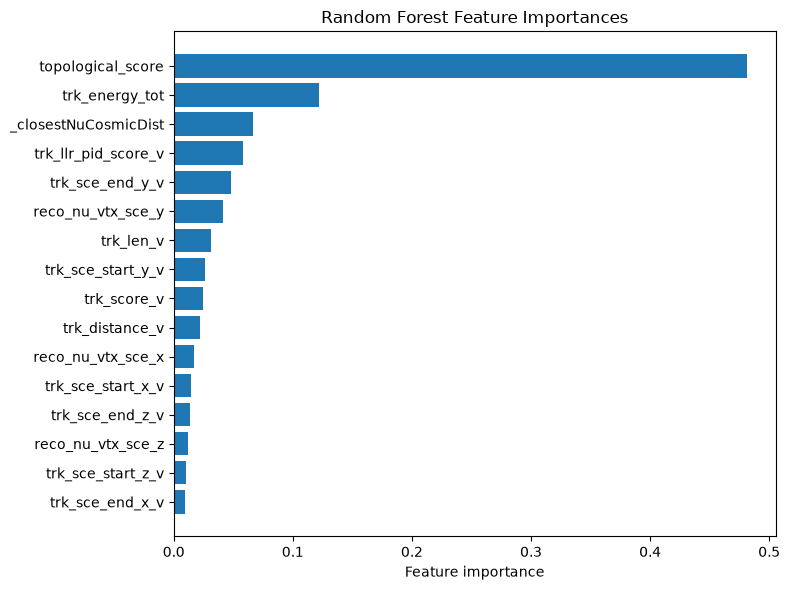

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "feature": features,
    "importance": rf_binary.feature_importances_
}).sort_values("importance", ascending=False)

print(importance_df)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(importance_df["feature"], importance_df["importance"])
ax.invert_yaxis()
ax.set_xlabel("Feature importance")
ax.set_title("Random Forest Feature Importances")
plt.tight_layout()
plt.show()